<a href="https://colab.research.google.com/github/shrijav22/ML_LAB_2026-2027/blob/main/mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**CLASSIFICATION ALGORITHMS**

Classification is a supervised machine learning technique used to predict the category or class of new data based on previously labelled training data.

In simple words, classification is used to divide data into different categories or classes.

Example: Predicting whether an email is Spam or Not Spam.



**Types of Classification Algorithms**
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. K-Nearest Neighbors (KNN)
5. Support Vector Machine (SVM)
6. Naive Bayes
7. Artificial Neural Network (ANN)

**Step 1: Import libraries**

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

**Step 2: Load the dataset**

In [33]:
# Load dataset
df = pd.read_csv('/content/vgsales.csv')

**Step 3: Data preprocessing**

In [34]:
# Remove rows with missing Publisher
df = df.dropna(subset=['Publisher'])

# Create sales categories
df['Sales_Category'] = pd.qcut(
    df['Global_Sales'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

# Select input features
X = df[['Platform', 'Year', 'Genre', 'Publisher']]

# Target variable
y = df['Sales_Category']

print(df[['Global_Sales', 'Sales_Category']].head())

print("\nSales Category Counts:")
print(y.value_counts())

   Global_Sales Sales_Category
0         82.74           High
1         40.24           High
2         35.82           High
3         33.00           High
4         31.37           High

Sales Category Counts:
Sales_Category
Low       5755
High      5428
Medium    5357
Name: count, dtype: int64


**Step 4: Split the dataset**

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (13232, 4)
Testing Data: (3308, 4)


**Step 5: Preprocessing categorical and numerical data**

In [36]:
# Numerical features
numeric_features = ['Year']

# Categorical features
categorical_features = ['Platform', 'Genre', 'Publisher']

# Numerical preprocessing
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])


**Step 6: Logistic Regression**

In [37]:
lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000))
])

lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, lr_pred))
print("LOGISTIC REGRESSION")
print(classification_report(y_test, lr_pred))

Logistic Regression Accuracy: 0.536577992744861
LOGISTIC REGRESSION
              precision    recall  f1-score   support

        High       0.57      0.64      0.60      1086
         Low       0.61      0.65      0.63      1151
      Medium       0.39      0.31      0.35      1071

    accuracy                           0.54      3308
   macro avg       0.52      0.53      0.53      3308
weighted avg       0.52      0.54      0.53      3308




**Step 7: Decision Tree**

In [38]:
dt_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth=15,
        random_state=42
    ))
])

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree Accuracy:",
      accuracy_score(y_test, dt_pred) )
print("DECISION TREE")
print(classification_report(y_test, dt_pred))

Decision Tree Accuracy: 0.48911729141475213
DECISION TREE
              precision    recall  f1-score   support

        High       0.58      0.44      0.50      1086
         Low       0.63      0.47      0.54      1151
      Medium       0.37      0.56      0.45      1071

    accuracy                           0.49      3308
   macro avg       0.53      0.49      0.49      3308
weighted avg       0.53      0.49      0.50      3308



**Step 8: K-Nearest Neighbors (KNN)**

In [39]:
knn_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)

knn_pred = knn_model.predict(X_test)

print("KNN Accuracy:",
      accuracy_score(y_test, knn_pred) )
print("KNN")
print(classification_report(y_test, knn_pred))

KNN Accuracy: 0.5021160822249093
KNN
              precision    recall  f1-score   support

        High       0.50      0.69      0.58      1086
         Low       0.59      0.53      0.56      1151
      Medium       0.39      0.28      0.32      1071

    accuracy                           0.50      3308
   macro avg       0.49      0.50      0.49      3308
weighted avg       0.50      0.50      0.49      3308



**Step 9: Support Vector Machine (SVM)**

In [40]:
svm_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LinearSVC(
        max_iter=5000,
        random_state=42
    ))
])

svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)

print("SVM Accuracy:",
      accuracy_score(y_test, svm_pred) )
print("SVM")
print(classification_report(y_test, svm_pred))

SVM Accuracy: 0.5389963724304716
SVM
              precision    recall  f1-score   support

        High       0.56      0.67      0.61      1086
         Low       0.61      0.65      0.63      1151
      Medium       0.39      0.28      0.33      1071

    accuracy                           0.54      3308
   macro avg       0.52      0.54      0.52      3308
weighted avg       0.52      0.54      0.53      3308



**Step 10: Compare all four algorithms**

In [41]:
results = pd.DataFrame({
    'Algorithm': [
        'Logistic Regression',
        'Decision Tree',
        'KNN',
        'SVM'
    ],

    'Accuracy': [
        accuracy_score(y_test, lr_pred) ,
        accuracy_score(y_test, dt_pred) ,
        accuracy_score(y_test, knn_pred) ,
        accuracy_score(y_test, svm_pred)
            ]
})

print(results)

             Algorithm  Accuracy
0  Logistic Regression  0.536578
1        Decision Tree  0.489117
2                  KNN  0.502116
3                  SVM  0.538996


**Step 11: Visualize accuracy compariso**n

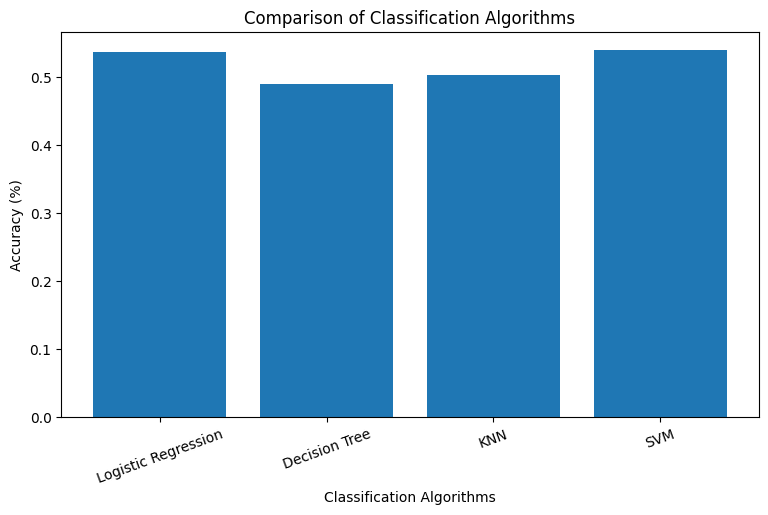

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(results['Algorithm'], results['Accuracy'])

plt.xlabel('Classification Algorithms')
plt.ylabel('Accuracy (%)')
plt.title('Comparison of Classification Algorithms')

plt.xticks(rotation=20)

plt.show()

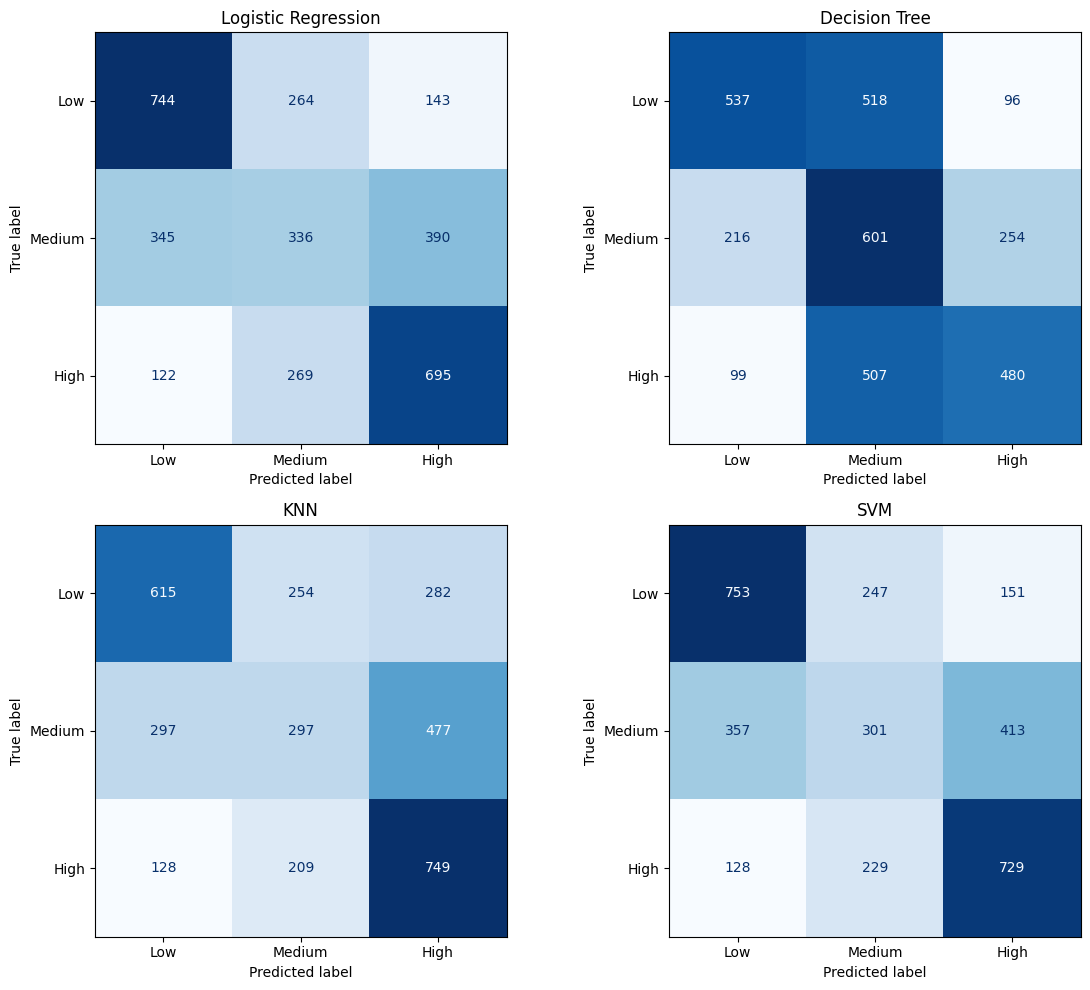

In [50]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Store predictions
models = {
    'Logistic Regression': lr_pred,
    'Decision Tree': dt_pred,
    'KNN': knn_pred,
    'SVM': svm_pred
}

labels = ['Low', 'Medium', 'High']

# Create 4 confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes = axes.flatten()

for i, (name, predictions) in enumerate(models.items()):

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=labels
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    )

    display.plot(
        ax=axes[i],
        cmap='Blues',
        values_format='d',
        colorbar=False
    )

    axes[i].set_title(name)

plt.tight_layout()
plt.show()